# Learning an O(3)-equivariant flow through its quotient

A scalar $a$ and a vector $v\in\mathbb R^3$ evolve together, but the dynamics do not depend on the direction of $v$. Can a two-dimensional learned model preserve the recurrent structure and recover the local indices of the four-dimensional flow?

This example starts with the physical orbit coordinates $(a,r)$, where $r=\|v\|$. It learns positive corrections to those coordinates, a time-step map, and an orbit representative. Learned coordinates are denoted by $\xi$ in formulas and by $(q_1,q_2)$ in the plots. The physical and learned coordinate planes should not be identified point by point.


## Run this example

The saved outputs can be read without running Python. To reproduce them, install the two pinned environments using [the setup instructions](../README.md#run-locally), choose the `code-kaito/.venv` kernel, and run the cells in order. The default loads the supplied trained model and does not retrain it.

The setup cell finds the example folder and calls `workspace` from `src/notebook_support.py`. It restores the bundled model weights and numerical evidence, checks dependency versions and input hashes, and prepares plotting caches. `ROOT` is the example folder. `EXAMPLES` and `DATA` identify the checked numerical dependency and its inputs. No model is fitted in this cell.


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "upstream.json").is_file())
sys.path.insert(0, str(ROOT / "src"))
from notebook_support import workspace
ROOT, EXAMPLES, DATA = workspace()


Pinned dependencies 21acca6 and numerical input checksums verified.


## Flow and physical quotient

Let $X=[-1.5,1.5]\times B^3_{1.5}$, where $B^3_{1.5}=\{v\in\mathbb R^3:\|v\|\le1.5\}$. For $(a,v)\in X$,
$$\dot a=a(1-a^2),\qquad \dot v=(1-2a^2-\|v\|^2)v.$$
The action is $(a,v)\mapsto(a,Qv)$ for $Q\in O(3)$, including reflections. The physical quotient is $q:X\to R=[-1.5,1.5]\times[0,1.5]$, $q(a,v)=(a,r)$ with $r=\|v\|$. For the flow $F_t:X\to X$, the quotient time-$\log3$ map $\bar F:R\to R$ is
$$\bar F(a,r)=\left(\frac{3a}{\sqrt d},\frac{3r}{\sqrt{d(d+8r^2)}}\right),\qquad d=1+8a^2.$$
The origin is repelling, $(0,1)$ is a saddle, and $(\pm1,0)$ attract. The fiber above $(0,1)$ is an equilibrium sphere.

For example, $(a,v)=(1/2,(1,0,0))$ and $(1/2,(0,1,0))$ have the same quotient $(1/2,1)$. For either state, $d=3$ and
$$\bar F(1/2,1)=\left(\frac{\sqrt3}{2},\frac3{\sqrt{33}}\right).$$
The scalar increases while the radius decreases. Every nonzero-radius fiber is a sphere of directions. At radius zero it collapses to one point.

`show_flow("o3")`, from `src/example_plots.py`, evaluates the analytical quotient trajectories and draws their direction arrows. The portrait shows the invariant upper unit half-disk. The training domain is the larger rectangle $R$, and the later basin display uses sampled one-step-image cells.


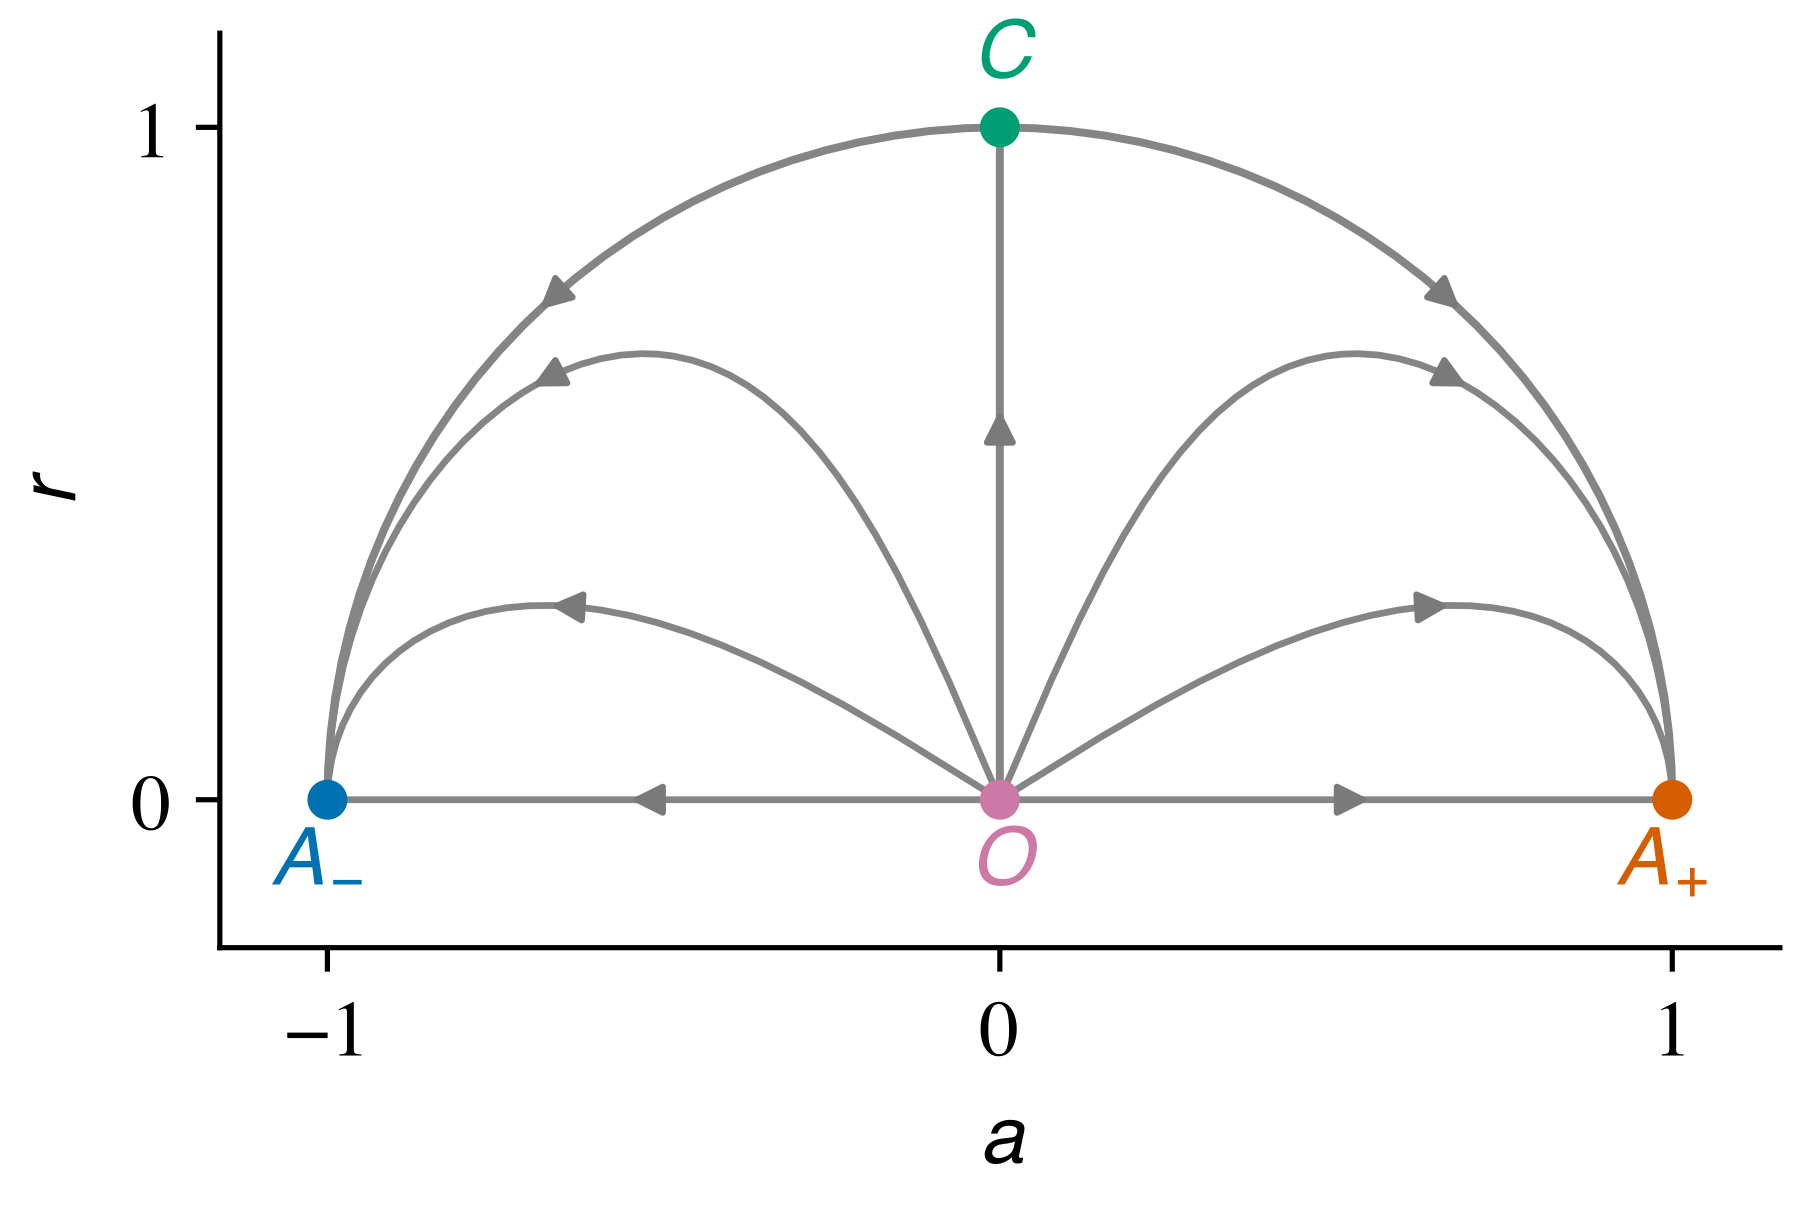

In [2]:
from example_plots import show_flow
reference = show_flow("o3")


## Learn corrections to the orbit coordinates

The encoder assigns one coordinate pair to every orthogonal orbit. Its known factor $(a,\|v\|)$ supplies the quotient geometry. The network learns a positive rescaling of each coordinate. The map advances the learned coordinates, and the decoder returns a representative with vector direction $(1,0,0)$.

An equivariant multilayer perceptron (EMLP) enforces the specified symmetry in its layers. Its encoder has one scalar and one three-dimensional vector input and two invariant scalar outputs. The map and decoder networks have scalar representations. Objax supplies differentiation and optimization.

Let $H=\mathbb R\times[0,\infty)$. An invariant network $N_\theta:\mathbb R^4\to\mathbb R^2$ defines $E_\theta:X\to H$,
$$E_\theta(x)=q(x)\odot\exp(0.25\tanh N_\theta(S^{-1}x)).$$
The diagonal matrix $S$ contains the training-pair RMS scalar scale and a shared RMS vector-component scale. The encoder explicitly uses the known invariants $(a,\|v\|)$ and learns positive corrections.

For networks $N_\psi,N_\phi:H\to\mathbb R^2$, define gains $g_\psi,k_\phi:H\to(0,\infty)^2$, the learned map $f_\psi:H\to H$, and quotient decoder $\widehat q_\phi:H\to H$ by
$$g_\psi(\xi)=\exp(3\tanh(N_\psi(\xi)/3)).$$
$$f_\psi(\xi)=\xi\odot g_\psi(\xi),$$
$$k_\phi(\xi)=\exp(0.5\tanh N_\phi(\xi)),\qquad\widehat q_\phi(\xi)=\xi\odot k_\phi(\xi).$$
Exponentials and products act componentwise. The representative decoder $D_\phi:H\to\mathbb R^4$ is $D_\phi(\xi)=(\widehat q_{\phi,1}(\xi),\widehat q_{\phi,2}(\xi),0,0)$. Its output need not lie in $X$. Positive gains preserve signs and coordinate axes, but do not ensure $f_\psi(E_\theta(X))\subseteq E_\theta(X)$.


## What the training objective measures

With $\tau=\log3$, use pairs $x^+=F_\tau(x)$. Let $u$ range over both members of the training pairs. The state scale is $s=1.5$ and the latent dimension is $m=2$. Write $E=E_\theta$, $f=f_\psi$, and $D=D_\phi$. The orbit distance $d_G:\mathbb R^{4}\times\mathbb R^{4}\to[0,\infty)$ minimizes Euclidean distance over the stated orthogonal action. The training loss is

$$L=L_{\rm rec}+L_{\rm pred}+L_{\rm con}+0.1L_{\rm cyc}+0.01L_{\rm spread},$$
$$L_{\rm rec}=\mathbb E_u\frac{d_G(D(E(u)),u)^2}{s^2}.$$
$$L_{\rm pred}=\mathbb E_x\frac{d_G(D(f(E(x))),x^+)^2}{s^2},$$
$$L_{\rm con}=\frac1m\mathbb E_x\|f(E(x))-E(x^+)\|^2.$$
$$L_{\rm cyc}=\frac1m\mathbb E_u\|E(D(E(u)))-E(u)\|^2,$$
$$L_{\rm spread}=\frac1m\sum_{j=1}^m\bigl(\operatorname{std}_u E_j(u)-0.5\bigr)^2.$$

Cycle evaluation uses the encoder formula on the decoded representatives.

Here $d_G((a,v),(\widehat a,\widehat v))^2=(a-\widehat a)^2+(\|v\|-\|\widehat v\|)^2$. The encoder formula extends to $\mathbb R^4$ for cycle evaluation. Latent coordinates are not standardized further.

Reconstruction checks whether the encoder and decoder preserve the orbit of a state. Prediction advances the encoded state before decoding. Consistency compares that latent prediction with the encoding of the observed next state. Cycle consistency encodes a decoded representative again. The spread term discourages collapse to a constant latent coordinate. Expectations and standard deviations in the training loss are empirical batch quantities. The optimizer is Adam, and the saved weights minimize the recorded validation loss.


## Load the trained model

All three EMLP/Objax networks have width 32 and two layers. Joint training uses batches of 256, 20,000 updates, and learning rate decaying from $10^{-3}$ to $2\cdot10^{-5}$. Training, validation, and test sets contain 16,384, 4,096, and 4,096 points. Scalar and radius are sampled uniformly on their intervals and directions uniformly on $S^2$. This is not uniform volume sampling in $X$. No special points are inserted. Validation loss selects the checkpoint before CMGDB.

`fit_quotient`, from `src/quotient_fitting.py`, resolves this configuration to its supplied checkpoint, verifies the weights, and returns its fit directory. With `retrain=False`, the curve below is the saved training history. Blue is batch loss and orange is validation loss. The architecture and loss used to create the checkpoint are specified above. Changing to `retrain=True` runs that training configuration again.


Loaded raw-state o3 quotient fit (seed 0).


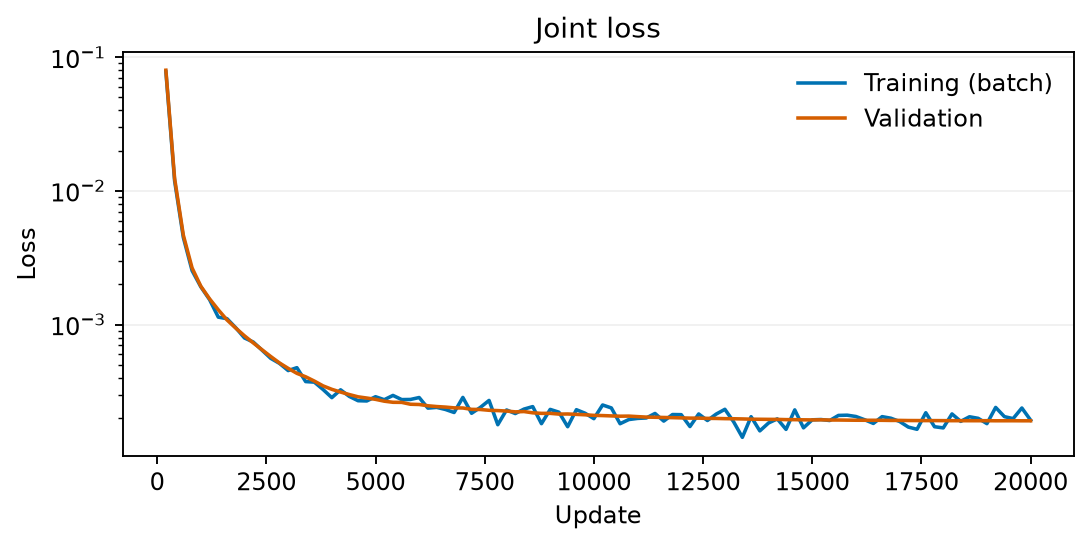

In [3]:
import numpy as np
from quotient_fitting import fit_quotient
fit = fit_quotient("o3", training="joint", parameterization="gain", seed=0,
                   train_starts=16384, validation_starts=4096, test_starts=4096,
                   joint_steps=20000, training_boundary_fraction=0.0,
                   validation_boundary_fraction=0.0, time_step=float(np.log(3)),
                   cmgdb_iterations=1, width=32, layers=2, batch_size=256,
                   learning_rate=1e-3, minimum_learning_rate=2e-5,
                   cycle_weight=0.1, spread_weight=0.01,
                   retrain=False, live=True)


## Read the learned model

`show_quotient_fit`, from `src/quotient_notebook.py`, reads the saved evaluation arrays. The left panel is the image of a regular physical $(a,r)$ grid under the encoder. The middle shows one-step learned displacements in $(q_1,q_2)$ coordinates. The right compares decoded and true orbit coordinates on the test set.

The table gives root-mean-square orbit distance divided by the state scale $1.5$. One step lasts $\log3$, and ten steps last $10\log3$. The ten-step error advances the latent state repeatedly before decoding. These test states are separate from the validation states used to choose the weights.


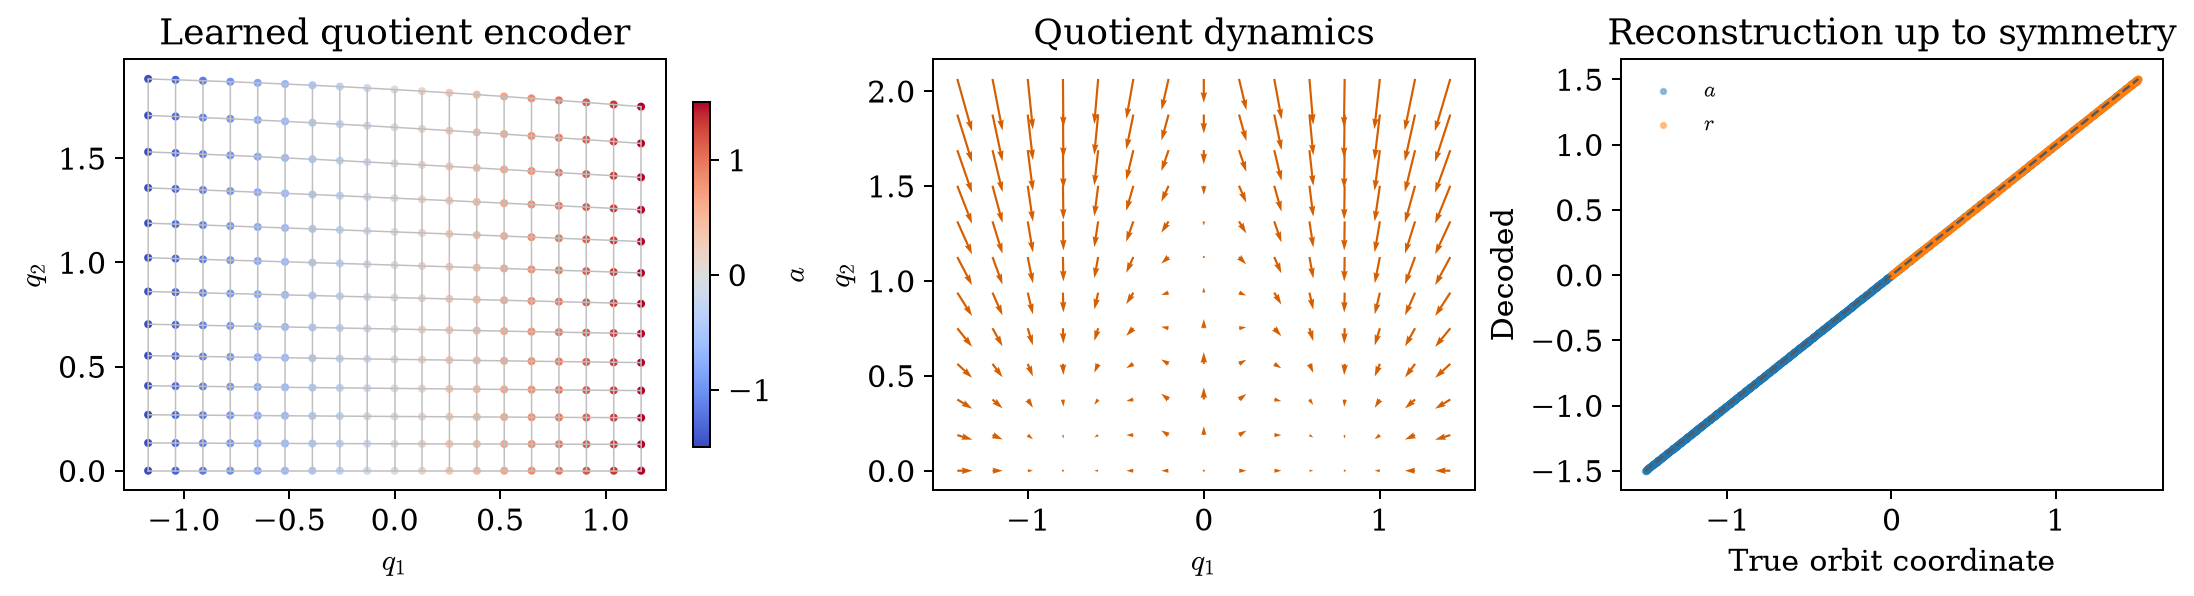

Held-out orbit RMS / state scale,Reconstruction,One step,Ten steps
Raw states,0.10%,0.38%,0.22%


In [4]:
from quotient_notebook import show_quotient_fit
show_quotient_fit(fit)


## Compare recurrent dynamics

Each rectangular cell uses a $5\times5$ sample grid. Image hulls are inflated by $10^{-9}$, with the radius lower bound clipped at zero. CMGDB computes native components and relative-chain indices over $\mathbb F_5$. Aggregation includes connecting cells and recomputes indices. The learned graphs have six native components and four aggregates on the $64^2$, $128^2$, and $256^2$ grids, with ordering $O\to C\to A_\pm$. Matched-time analytical graphs have 4, 5, and 4 native components. The displayed basin colors use a sampled $64^2$ one-step-image cell union in each model's coordinates. White cells are uncolored, not necessarily outside a basin.

### Reading the Morse graphs

A **Morse set** collects recurrent behavior such as an equilibrium or an invariant circle. In the cell graph, recurrent strongly connected components give the **native** nodes. An arrow records a possible transition in this finite graph. It need not prove an orbit of the ODE exists. An **aggregate** joins nearby nodes together with their connecting cells, after which its index is recomputed.

The Conley index records the topology of a neighborhood relative to the part of its boundary through which trajectories leave. Its homology groups $H_k$ are vector spaces over $\mathbb F_5$, the field of integers modulo five. A node annotation lists the index-map polynomials in degrees $0,1,2,\ldots$. In these figures, `0` means no nonzero Conley homology in that degree and `x-1` means a one-dimensional class with identity map. The `x` in this label is a formal polynomial variable, not a state coordinate. For example, `(0, x-1, 0)` has only $H_1=\mathbb F_5$. Numbers attached to native nodes are component identifiers, not coordinates or stability ranks.

### Recover the fiber contribution

Writing $g_\psi=(g_1,g_2)$, the specified lift $\widetilde F:\mathbb R^4\to\mathbb R^4$ is
$$\widetilde F(s,w)=(s g_1(s,\|w\|),g_2(s,\|w\|)w).$$
It preserves fiber direction. Arb interval arithmetic bounds verify local indices $H_4$ at the origin, $H_1,H_3$ at the saddle sphere, and $H_0$ at the sinks, with identity maps over $\mathbb F_5$. The fiber direction is fixed, so the lift has degree $+1$ on each nonzero-radius sphere.

`quotient_domain_study`, from `src/quotient_domain_notebook.py`, loads the matching saved study or evaluates the cell samples and runs CMGDB if it is absent. Level $\ell$ uses $2^\ell$ cells on each axis. `show_joint_comparison`, from `src/o3_joint_comparison.py`, evaluates the analytical map at the same time step, reads the learned graphs, and displays the comparison and recomputed aggregates.

Read the columns separately. Each uses its own coordinates. Solid cells mark native Morse sets, colored by aggregate. Pale colors show reachability in the sampled one-step image. Pale green marks paths from $O$ to $C$. White cells are uncolored, not necessarily outside a basin. The middle row gives quotient indices, and the bottom row gives indices of the specified lift.


Grid per axis,Analytical time 1.099,Learned rectangle,Learned encoder image
32,4,8,8
64,4,6,6
128,5,6,6
256,4,6,6


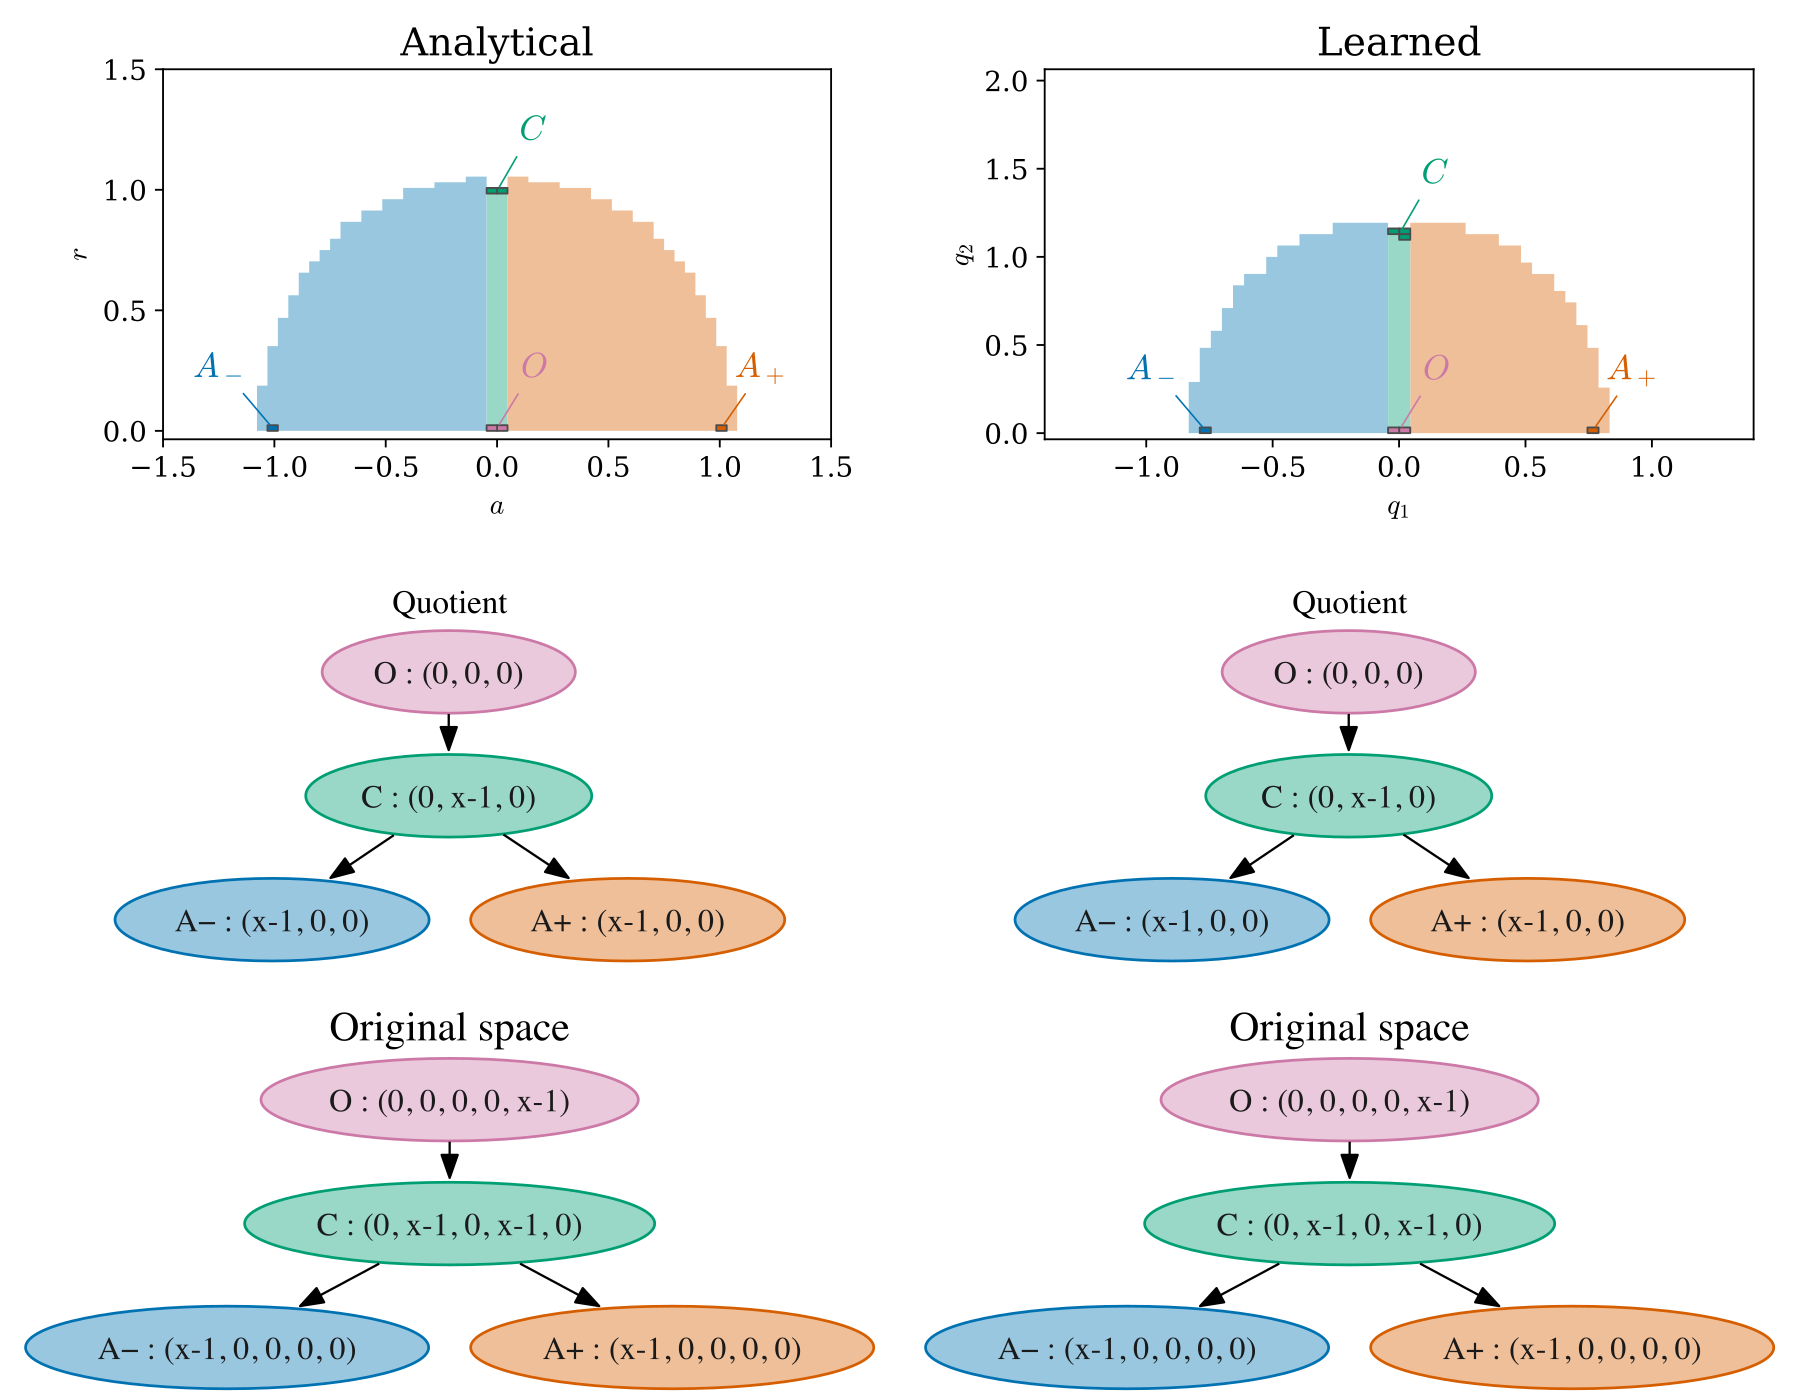

**64 × 64 cells.** Solid colors mark native Morse cells by aggregate. Pale colors show finite-graph reachability on the sampled one-step image. Each column uses its own quotient coordinates.

Grid,Native learned,Aggregated,Analytical graph + indices
64,6,4,Match
128,6,4,Match
256,6,4,Match


In [5]:
from quotient_domain_notebook import quotient_domain_study
from o3_joint_comparison import show_joint_comparison
study = quotient_domain_study(fit, levels=(5, 6, 7, 8))
show_joint_comparison(reference, fit, study, diagnostics=False)


### Separate quotient classes from fiber classes

`show_reconstruction`, from `src/o3_reconstruction.py`, checks the saved local interval certificate against this checkpoint and assembles the relative-homology contribution of the sphere fibers. The output separates classes already visible in the quotient from those added by the fibers. In particular, the origin's $H_4$ class is invisible in the quotient, and the saddle sphere gains an $H_3$ class.


In [6]:
from o3_reconstruction import show_reconstruction
reconstruction = show_reconstruction(fit)


### Original-space reconstruction

The nonzero-radius fibers are $S^2$ and collapse on $P=\{r=0\}$. For the specified direction-preserving lift, let $(B,L)$ be a quotient index pair, with isolating neighborhood $B$ and exit set $L$. Its lifted pair is $(N_X,L_X)$. With coefficients in $\mathbb F_5$,

$$H_k(N_X,L_X) \cong H_k(B,L)\oplus H_{k-2}(B,L\cup(B\cap P)).$$

Arb interval bounds verify local expansion/contraction and unique fixed-point brackets for this saved map. These give a local isolating continuation to the positive normal forms, whose index maps are identities. CMGDB computes the relative-chain indices over $\mathbb F_5$; entries below run from degree 0 to 4.


Set,Quotient classes,Additional original-space classes,Original-space classes
Origin,None,H₄,H₄
Saddle sphere,H₁,H₃,"H₁, H₃"
Each sink,H₀,None,H₀


The quotient graph alone does not determine the fiber degree. The specified lift has degree +1. Local bounds are restored to `build/o3-certification/local-index-argument.md`.

## Check the sampled domain and native graphs

The finite encoder image $Z=E_\theta(X)$ lies in $H$, but the positive-gain formula alone does not prove that $f_\psi(Z)\subseteq Z$. The study approximates $Z$ by encoding a densely sampled boundary of the physical rectangle and checks the images of 8,181 encoded states. It does not project escaping points back into that image.

`show_joint_diagnostics`, from `src/o3_joint_comparison.py`, displays this membership check and compares two graph domains. The rectangular graph has CMGDB index annotations. The graph restricted to the sampled encoder image is computed with the Atlas interface and has no index annotations. Rectangle indices are not assigned to its nodes.


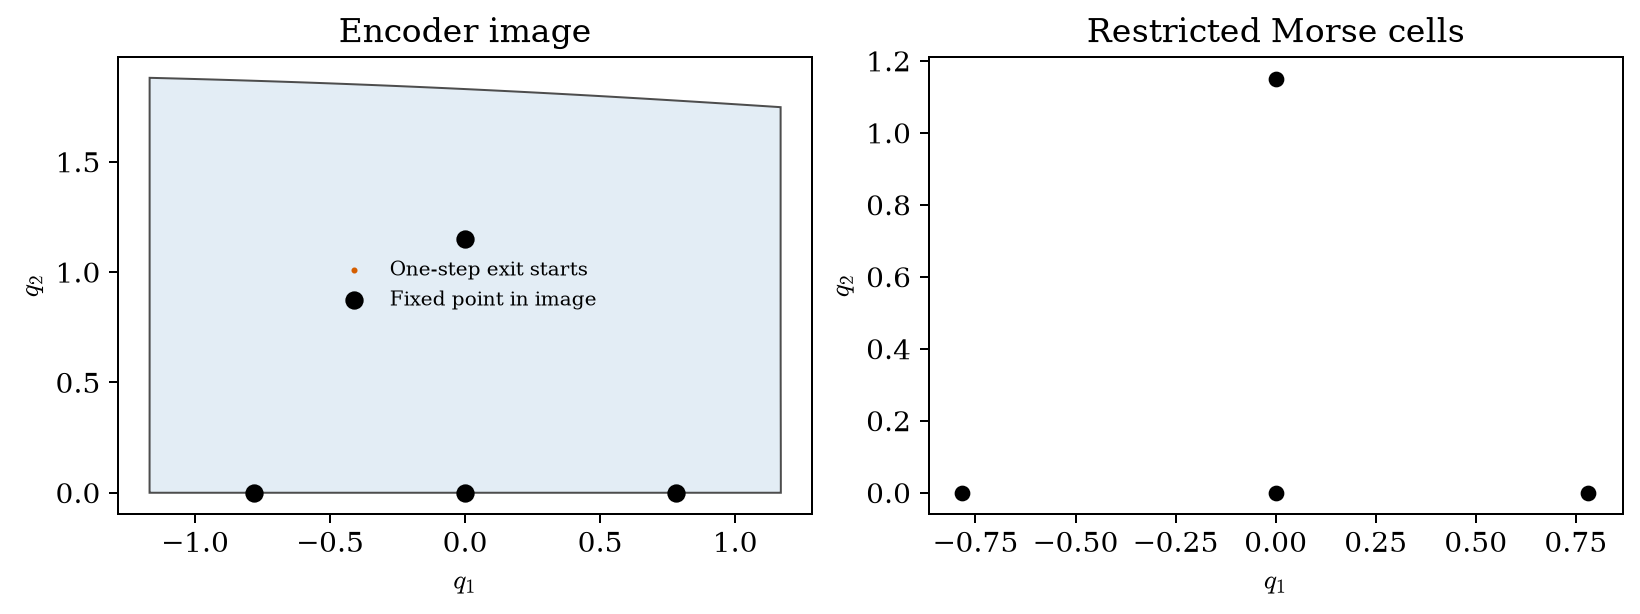

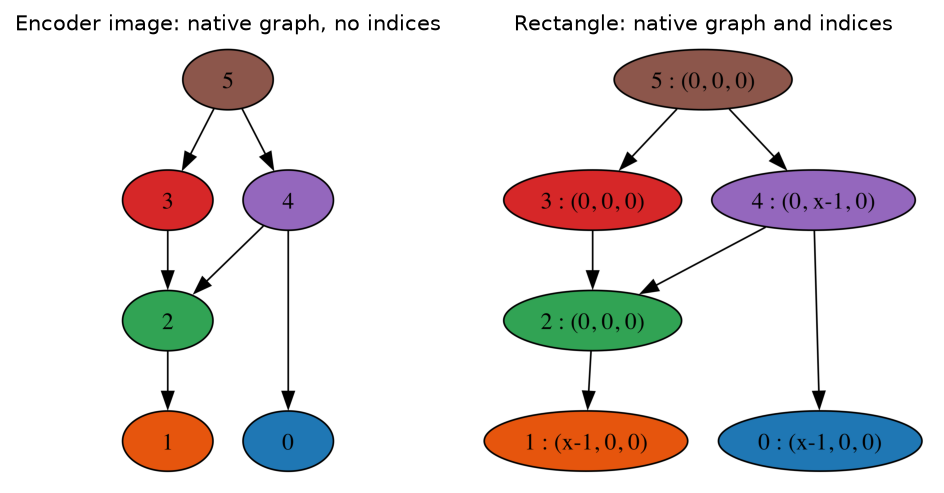

In [7]:
from o3_joint_comparison import show_joint_diagnostics
show_joint_diagnostics(fit, study)


## What transfers to the physical flow

The displayed graph is computed from sampled cell-image hulls. The local index bounds concern the explicitly specified lift. To identify its dynamics with the physical ODE through the encoder would also require suitable encoder coordinates and a uniform model-error bound that preserves isolation along a continuation.

At a physical quotient fixed point, choose a representative $x_*$. Since the encoder is invariant, $E(F_\tau(x_*))=E(x_*)$, even if the state rotates along its orbit. Thus $\|f(E(x_*))-E(x_*)\|$ measures failure of the desired commutation relation at that orbit. A small value is a useful diagnostic, but does not bound the error on a neighborhood.

`show_conjugacy_check`, from `src/conjugacy_summary.py`, matches the checkpoint hash to the saved fixed-point evaluations and reports these defects. The geometry count is the number of sampled encoder derivatives (sphere) or Jacobian determinants (O(3)). Positivity on those samples is not a global invertibility proof.


In [8]:
from conjugacy_summary import show_conjugacy_check
show_conjugacy_check(fit)


Quantity,Value
"Largest fixed-point defect, one step",0.0039923
"Largest fixed-point defect, CMGDB horizon",0.0039923
Encoder geometry sample count,3185
